Den Dateinamen eingeben (optional):  CPU_neu


--- Messung beendet ---
Durchschnittliche Auslastung: 4.27%
Maximale Auslastung: 7.44%
Gespeichert unter:  /home/skramer/Linux_PC/Programmieren/Python/Python_eigene_Scripte / 2026-11-05_07-04-53_CPU_neu.png


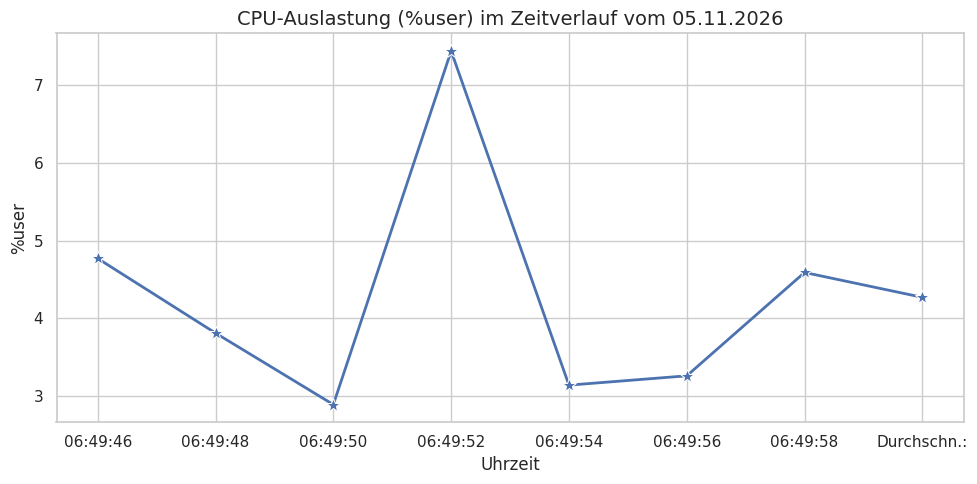

In [11]:
import subprocess
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import datetime
from pathlib import Path

eingabe_name = input("Den Dateinamen eingeben (optional): ").strip()
zeitstempel = datetime.datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

if eingabe_name:
    dateinamen = f"{zeitstempel}_{eingabe_name}"
else:
    dateinamen = f"cpu_auslastung_{zeitstempel}"

# sar ausführen

try:
    result = subprocess.run(["sar", "-u", "2", "7"], capture_output=True, text=True, check=True)
except (subprocess.SubprocessError, FileNotFoundError):
    print("Fehler: 'sar' konnte nicht ausgeführt werden. Ist sysstat installiert?")
    exit(1)

zeiten = []
user_werte = []

# Zeilen durchgehen und parsen
for line in lines:
    parts = line.split()
    # Wir filtern Zeilen heraus, die mit einer Uhrzeit beginnen (enthalten ":") 
    # und sich auf "all" beziehen.
    if len(parts) >= 3 and ":" in parts[0] and parts[1] == "all":
        zeit = parts[0]
        # Deutsches Komma (z.B. "8,11") in float-kompatiblen Punkt ("8.11") umwandeln
        user_val = float(parts[2].replace(',', '.'))
        
        zeiten.append(zeit)
        user_werte.append(user_val)

# In ein Pandas-DataFrame überführen (ideal für Seaborn)
df = pd.DataFrame({
    "Zeit": zeiten,
    "Auslastung": user_werte
})

#print(df) # Zum Kontrollieren in der Konsole

# Visualisierung mit Seaborn
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))

# Ein Lineplot oder Barplot auf Basis des DataFrames
sns.lineplot(data=df, x="Zeit", y="Auslastung", marker='*', color='b', linewidth=2, markersize=10)

plt.title(f"CPU-Auslastung (%user) im Zeitverlauf vom {datumeinfuegen}", fontsize=14)
plt.xlabel("Uhrzeit", fontsize=12)
plt.ylabel("%user", fontsize=12)
plt.xticks(rotation=0)
plt.tight_layout()

# Statistiken berechnen
avg_last = df["Auslastung"].mean()
max_last = df["Auslastung"].max()

print(f"--- Messung beendet ---")
print(f"Durchschnittliche Auslastung: {avg_last:.2f}%")
print(f"Maximale Auslastung: {max_last:.2f}%")
print(f"Gespeichert unter:  {Path.cwd()} / {dateinamen}.png")
plt.savefig(f"{dateinamen}.png", dpi=300)
plt.show()